In [1]:
import numpy as np
import os
import json
import ast
import pandas as pd
from plotnine import (
    ggplot, aes, geom_line, geom_point, geom_errorbar, facet_wrap, geom_text,
    labs, theme_classic, theme, element_text, geom_vline, scale_y_continuous, geom_hline, scale_x_continuous, scale_color_manual, ggtitle, scale_shape_manual, position_dodge
)

In [2]:
stimColors = {'Rule': '#715cad', 'Exception': '#6fa8dcff'}

df = pd.read_csv('data/experiment1_raw.csv')
df = df[df['catch'] == False]

In [3]:
#  Count participants per curriculum 
n_per_curr = df.groupby('curriculum')['subjectId'].nunique().reset_index(name='n')
print(n_per_curr)
print("Total participants:", n_per_curr['n'].sum())

           curriculum   n
0  Complex\nTo Simple  72
1      No\nCurriculum  63
2  Simple\nTo Complex  72
Total participants: 207


/var/folders/1t/nrvh1_812fq_4bhspd0mgxlm0000gr/T/ipykernel_62506/1460838942.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
/Users/azhang/anaconda3/envs/reval/lib/python3.13/site-packages/plotnine/layer.py:372: PlotnineWarning: geom_errorbar : Removed 6 rows containing missing values.


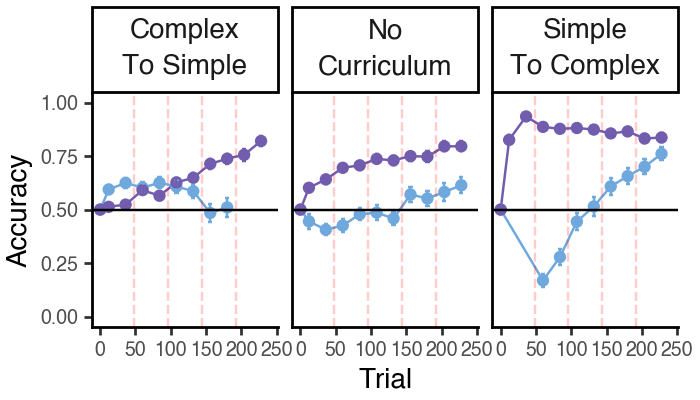

In [4]:
# Bin accuracy over trials of learning and plot by curriculumCondition (with n per condition)
bin_size = 24
df_learning = df[df['taskPart'] == 'learning']
df_learning['total_trial_num'] = (
    df_learning
      .sort_values(['subjectId', 'blockNum', 'trialNum'])
      .groupby('subjectId')
      .cumcount() + 1
)
df_learning = df_learning[df_learning['timeout'] == False]
df_learning['bin'] = ((df_learning['total_trial_num'] - 1) // bin_size) + 1
# Bin mid point for plotting (use trial number in x-axis)
df_learning['bin_mid'] = (df_learning['bin'] * bin_size - bin_size / 2).astype(float)

# Per-subject accuracy per bin
per_sub = (
    df_learning
    .groupby(['curriculum', 'subjectId','stimType', 'bin', 'bin_mid'], as_index=False)
    .agg(acc=('correct', 'mean'))
)

# Across-subject summary: mean and standard error (SE)
summary = (
    per_sub
    .groupby(['curriculum', 'stimType', 'bin', 'bin_mid'], as_index=False)
    .agg(mean_acc=('acc', 'mean'), se=('acc', lambda x: x.std(ddof=1) / np.sqrt(len(x))))
)
# Create ymin/ymax columns for errorbars
summary['ymin'] = summary['mean_acc'] - summary['se']
summary['ymax'] = summary['mean_acc'] + summary['se']

# Prepend a starting point at (0, 0.5) representing chance accuracy for each group
start_points = (
    summary[['curriculum', 'stimType']]
    .drop_duplicates()
    .reset_index(drop=True)
)
start_points['bin'] = 0
start_points['bin_mid'] = 0.0
start_points['mean_acc'] = 0.5
start_points['se'] = np.nan
start_points['ymin'] = np.nan
start_points['ymax'] = np.nan
summary = pd.concat([start_points, summary], ignore_index=True).sort_values(
    ['curriculum', 'stimType', 'bin_mid']
)

# Compute vertical lines every 48 trials (in trial number space)
max_trial = int(df_learning['total_trial_num'].max())
vlines = list(range(48, max_trial, 48))
# Put vlines into a small DataFrame so plotnine treats them as continuous values
vline_df = pd.DataFrame({'x': vlines}) if len(vlines) > 0 else pd.DataFrame({'x': []})

# Build the plot
p = (
    ggplot(summary, aes(x='bin_mid', y='mean_acc', color='stimType', group='stimType'))
    + geom_line()
    + geom_point()
    + geom_errorbar(aes(ymin='ymin', ymax='ymax'), width=6)
    + facet_wrap('~curriculum')
    + (geom_vline(mapping=aes(xintercept='x'), data=vline_df, color='red', linetype='dashed', alpha=0.2) if not vline_df.empty else 0)
    + geom_hline(yintercept=0.5, linetype='solid', color='black', alpha=1)
    + scale_x_continuous(limits=(0, max_trial))
    + scale_y_continuous(limits=(0, 1))
    + scale_color_manual(values=stimColors)
    + theme_classic()
    + labs(x='Trial', y='Accuracy', color='Stimulus Type')
    + theme(axis_text=element_text(size=7), text=element_text(size=10),figure_size=(3.5,2), panel_spacing_x=0.02, legend_position='none')
)
p

# p.save(
#     filename='analysis/figs/fig2C.svg',
#     format="svg",
#     verbose=False
# )

In [5]:
df_learning['total_trial_num'] = (
    df_learning
      .sort_values(['subjectId', 'blockNum', 'trialNum'])
      .groupby('subjectId')
      .cumcount() + 1
)

df_learning[df_learning['curriculum'] == "No\nCurriculum"].to_csv('data/exp1_learning_control.csv', index=False)

In [7]:
import psytrack as psy

no_curr = df_learning[df_learning['curriculum'] == "No\nCurriculum"]

# TODO: drop nas for timeout etc
no_curr['x1'] = no_curr['stimuli'].map(lambda x: (int(x[0])-0.5)*2)
no_curr['x2'] = no_curr['stimuli'].map(lambda x: (int(x[1])-0.5)*2)
no_curr['x3'] = no_curr['stimuli'].map(lambda x: (int(x[2])-0.5)*2)
no_curr['x1x2'] = no_curr.apply(lambda x: x['x1'] * x['x2'], axis=1)
no_curr['x1x3'] = no_curr.apply(lambda x: x['x1'] * x['x3'], axis=1)
no_curr['x2x3'] = no_curr.apply(lambda x: x['x2'] * x['x3'], axis=1)
no_curr['x1x2x3'] = no_curr.apply(lambda x: x['x1'] * x['x2'] * x['x3'], axis=1)
no_curr['correctResponse'] = no_curr['correctResponse'].astype(int)
no_curr['simple_rule'] = no_curr.apply(lambda x: 0 if x['stimType']=='Exception' else (x['correctResponse']-0.5)*2, axis=1)
no_curr['exception'] = no_curr.apply(lambda x: 0 if x['stimType']=='Rule' else (x['correctResponse']-0.5)*2, axis=1)
no_curr

/var/folders/1t/nrvh1_812fq_4bhspd0mgxlm0000gr/T/ipykernel_1483/2397750698.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
/var/folders/1t/nrvh1_812fq_4bhspd0mgxlm0000gr/T/ipykernel_1483/2397750698.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
/var/folders/1t/nrvh1_812fq_4bhspd0mgxlm0000gr/T/ipykernel_1483/2397750698.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documenta

,timeout,subjectId,rt,correctResponse,stimuli,catch,taskPart,responseCoded,correct,trialNum,...,bin_mid,x1,x2,x3,x1x2,x1x3,x2x3,x1x2x3,simple_rule,exception
0,False,0,3056.0,0,001,False,learning,0,1,0.0,...,12.0,-1.0,-1.0,1.0,1.0,-1.0,-1.0,1.0,-1.0,0.0
1,False,0,1202.0,0,110,False,learning,0,1,1.0,...,12.0,1.0,1.0,-1.0,1.0,-1.0,-1.0,-1.0,0.0,-1.0
2,False,0,744.0,1,011,False,learning,0,0,2.0,...,12.0,-1.0,1.0,1.0,-1.0,-1.0,1.0,-1.0,1.0,0.0
4,False,0,688.0,1,111,False,learning,0,0,4.0,...,12.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0
6,False,0,701.0,1,010,False,learning,0,0,6.0,...,12.0,-1.0,1.0,-1.0,-1.0,1.0,-1.0,1.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
58609,False,204,1307.0,1,100,False,learning,1,1,49.0,...,228.0,1.0,-1.0,-1.0,-1.0,-1.0,1.0,1.0,0.0,1.0
58610,False,204,2287.0,0,101,False,learning,0,1,50.0,...,228.0,1.0,-1.0,1.0,-1.0,1.0,-1.0,-1.0,-1.0,0.0
58611,False,204,1265.0,0,001,False,learning,0,1,51.0,...,228.0,-1.0,-1.0,1.0,1.0,-1.0,-1.0,1.0,-1.0,0.0
58612,False,204,1682.0,1,010,False,learning,1,1,52.0,...,228.0,-1.0,1.0,-1.0,-1.0,1.0,-1.0,1.0,1.0,0.0


/var/folders/1t/nrvh1_812fq_4bhspd0mgxlm0000gr/T/ipykernel_1483/3561820248.py:5: UserWarning: Boolean Series key will be reindexed to match DataFrame index.


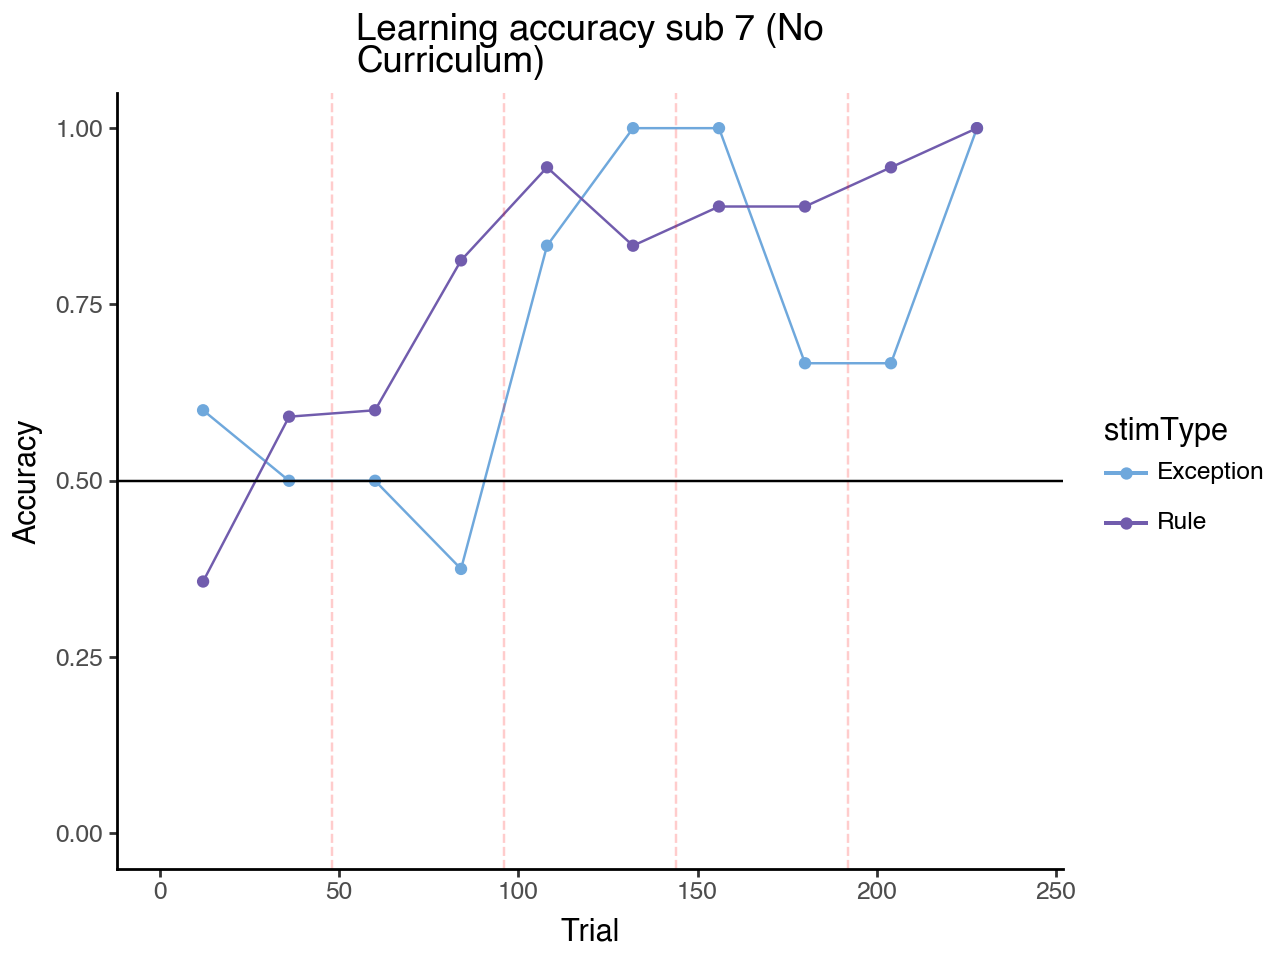

In [8]:
subject_id = 7
curriculum = df[df['subjectId']==subject_id].iloc[0]['curriculum']

# Filter learning trials for that subject
df_sub = no_curr[(df['taskPart'] == 'learning') & (df['subjectId'] == subject_id)].copy()

# Per-subject accuracy per bin
summary = (
    df_sub
    .groupby(['stimType', 'bin', 'bin_mid'], as_index=False)
    .agg(acc=('correct', 'mean'))
)

# Build the plot
p = (
    ggplot(summary, aes(x='bin_mid', y='acc', color='stimType', group='stimType'))
    + geom_line()
    + geom_point()
    + (geom_vline(mapping=aes(xintercept='x'), data=vline_df, color='red', linetype='dashed', alpha=0.2) if not vline_df.empty else 0)
    + geom_hline(yintercept=0.5, linetype='solid', color='black', alpha=1)
    + labs(x='Trial', y='Accuracy')
    + scale_x_continuous(limits=(0, max_trial))
    + scale_y_continuous(limits=(0, 1))
    + scale_color_manual(values=stimColors)
    + theme_classic()
    + theme(axis_text_x=element_text(rotation=0, ha='center'))
    + ggtitle(f"Learning accuracy sub {subject_id} ({curriculum})")
)

p


In [9]:
weights = {'bias': 1, 
           's1': 1,}

# It is often useful to have the total number of weights K in your model
K = np.sum([weights[i] for i in weights.keys()])

hyper= {'sigInit': 2**4.,      # Set to a single, large value for all weights. Will not be optimized further.
        'sigma': [2**-4.]*K,   # Each weight will have it's own sigma optimized, but all are initialized the same
        'sigDay': None}        # Indicates that session boundaries will be ignored in the optimization

optList = ['sigma']

inputs_dict = {'s1': np.array(df_sub[['x2']]), 's2': np.array(df_sub[['exception']])}
y = np.asarray(df_sub['responseCoded'].astype(float) + 1, dtype=np.float64)
D = {'y': y, 'inputs': inputs_dict}

hyp, evd, wMode, hess_info = psy.hyperOpt(D, hyper, weights, optList)
psy.plot_weights(wMode, weights)

RuntimeError: Factor is exactly singular

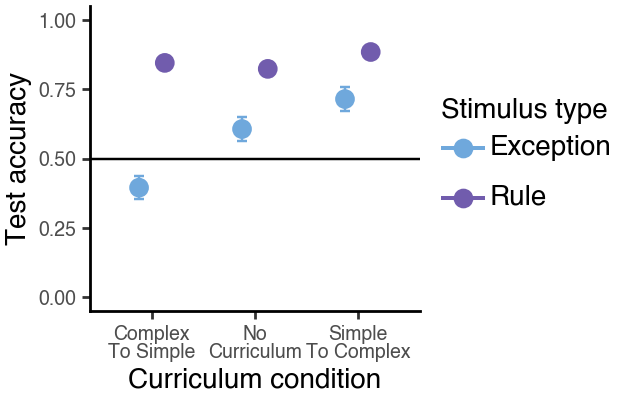

In [6]:
# Plot test-phase accuracy by curriculum and stimType 

test_df = df[(df['taskPart'] == 'test') & (df['timeout'] == False)]

# Per-subject accuracy in the test phase per curriculum and stimType
per_sub_test = (
    test_df
    .groupby(['curriculum','subjectId', 'stimType'], as_index=False)
    .agg(acc=('correct', 'mean'))
)

# Across-subject summary: mean and SE
summary_test = (
    per_sub_test
    .groupby(['curriculum', 'stimType'], as_index=False)
    .agg(mean_acc=('acc', 'mean'), se=('acc', lambda x: x.std(ddof=1) / np.sqrt(len(x))))
)
summary_test['ymin'] = summary_test['mean_acc'] - summary_test['se']
summary_test['ymax'] = summary_test['mean_acc'] + summary_test['se']

# Plot: curriculum on x-axis, accuracy on y-axis, stimType side-by-side
dodge = position_dodge(width=0.5)
p_test = (
    ggplot(summary_test, aes(x='curriculum', y='mean_acc', color='stimType'))
    + geom_point(position=dodge, size=3)
    + geom_errorbar(aes(ymin='ymin', ymax='ymax'), width=0.2, position=dodge)
    + labs(x='Curriculum condition', y='Test accuracy', color='Stimulus type')
    + scale_y_continuous(limits=(0, 1))
    + scale_color_manual(values=stimColors)
    + theme_classic()
    + geom_hline(yintercept=0.5, linetype='solid', color='black', alpha=1)
    # make x tick labels larger and not tilted
    + theme(axis_text_x=element_text(rotation=0, ha='center', size=11))
    + theme(axis_text=element_text(size=7), text=element_text(size=10),figure_size=(3.1,2))
)

p_test

# p_test.save(
#     filename='analysis/figs/fig2D.svg',
#     format="svg",
#     verbose=False
# )

In [ ]:
# test_df[test_df['curriculum'] == "No\nCurriculum"].to_csv('data/exp1_test_control.csv', index=False)
# test_df.to_csv('data/exp1_test.csv', index=False)